In [17]:
!pip install yfinance


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import pandas as pd
import yfinance as yf
from datetime import datetime

In [19]:
!pip install matplotlib
!pip install pandas
!pip install tensorflow
!pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
ticker ="AAPL"
start_date ="2000-01-01"
end_date = datetime.now().strftime("%Y-%m-%d")

data = yf.download(ticker, start=start_date, end= end_date,interval='1d')
data

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2000-01-03,0.836367,0.840570,0.759782,0.783598,535796800
2000-01-04,0.765853,0.826560,0.756046,0.808815,512377600
2000-01-05,0.777060,0.826093,0.769588,0.775192,778321600
2000-01-06,0.709814,0.799475,0.709814,0.792938,767972800
2000-01-07,0.743438,0.754645,0.713551,0.721022,460734400
...,...,...,...,...,...
2026-11-16,352.779999,357.130005,351.309998,357.130005,50292200
2026-11-17,351.910004,355.359985,349.670013,352.829987,37407500


In [21]:
df = data[['Close']]
df.head()

Price,Close
Ticker,AAPL
Date,
2000-01-03,0.836367
2000-01-04,0.765853
2000-01-05,0.777060
2000-01-06,0.709814
2000-01-07,0.743438


In [22]:
df.isnull().sum()

Price  Ticker
Close  AAPL      0
dtype: int64

In [23]:
from sklearn.preprocessing import MinMaxScaler
m = MinMaxScaler(feature_range=(0,1))
df_scaled = m.fit_transform(df)
df_scaled

array([[0.00179825],
       [0.00160021],
       [0.00163169],
       ...,
       [0.98927196],
       [0.98017266],
       [0.96149678]], shape=(6763, 1))

In [24]:
import numpy as np

In [25]:

def create_dataset(x,y,steps=1):
  xdata,ydata=[],[]
  for i in range (len(x)-steps):
    xdata.append(x[i:(i+steps),0])
    ydata.append(x[i+steps,0])
  return np.array(xdata),np.array(ydata)
steps=60
x,y = create_dataset(df_scaled,df_scaled,steps)


In [26]:
x

array([[0.00179825, 0.00160021, 0.00163169, ..., 0.00235956, 0.00237792,
        0.00236874],
       [0.00160021, 0.00163169, 0.00144283, ..., 0.00237792, 0.00236874,
        0.00230185],
       [0.00163169, 0.00144283, 0.00153726, ..., 0.00236874, 0.00230185,
        0.00208808],
       ...,
       [0.86911346, 0.87907581, 0.88224683, ..., 1.        , 0.99019869,
        0.98775539],
       [0.87907581, 0.88224683, 0.89661497, ..., 0.99019869, 0.98775539,
        0.98927196],
       [0.88224683, 0.89661497, 0.88861708, ..., 0.98775539, 0.98927196,
        0.98017266]], shape=(6703, 60))

In [27]:
y

array([0.00230185, 0.00208808, 0.00229923, ..., 0.98927196, 0.98017266,
       0.96149678], shape=(6703,))

In [28]:
x.shape

(6703, 60)

In [29]:
y.shape

(6703,)

In [30]:
x= np.reshape(x,(x.shape[0],x.shape[1],1))
x.shape

(6703, 60, 1)

In [31]:
from tensorflow.keras.layers import LSTM,Dense,Dropout
from tensorflow.keras.models import Sequential

In [32]:

model = Sequential()
model.add(LSTM(50,return_sequences=True,input_shape=(steps,1)))
model.add(LSTM(50))
model.add(Dropout(.3))
model.add(Dense(1))

c:\Users\tejaswini patil\OneDrive\Documents\StockForcastingDeployment\venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [33]:
model.compile(optimizer='adam',loss='mse')

In [34]:
model.fit(x,y,epochs=2,batch_size=8)

Epoch 1/2
838/838 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - loss: 0.0019
Epoch 2/2
838/838 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - loss: 0.0011


In [35]:
forecast_period = 30
last_data_point =df_scaled[-steps:]
forecasted_prices = []

for i in range(forecast_period):
  prediction = model.predict(np.array([last_data_point]))
  forecasted_prices.append(m.inverse_transform(prediction)[0,0])

  last_data_point = np.append(last_data_point[1:],prediction,axis=0)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━

In [36]:
from datetime import timedelta
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

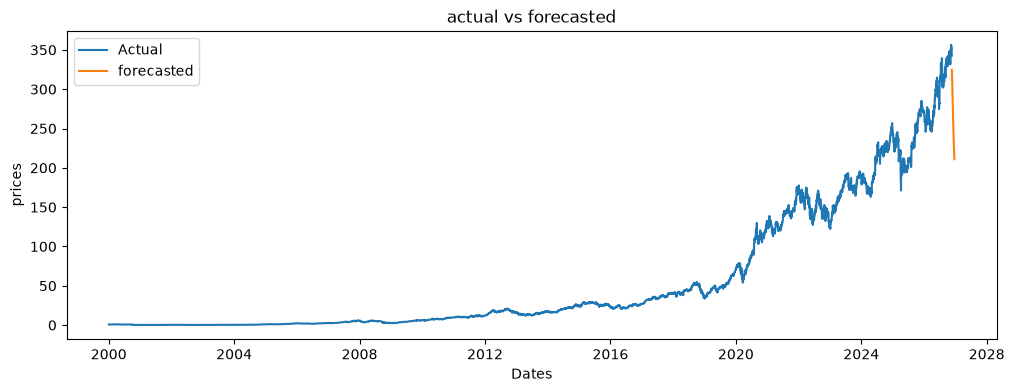

In [37]:
last_date = df.index[-1].to_pydatetime()
forecast_dates =[last_date + timedelta(days=i)for i in range(1,forecast_period + 1)]
forecast_dates_num = mdates.date2num(forecast_dates)


plt.figure(figsize=[12,4])
plt.plot(df.index,df[['Close']],label='Actual')
plt.plot(forecast_dates,forecasted_prices,label='forecasted')
plt.ylabel('prices')
plt.xlabel('Dates')
plt.title('actual vs forecasted')
plt.legend()
plt.show()